# The gamma distribution

- [Gamma function](#gamma-function)
  - [Definition](#gamma-function)
  - [Properties](#properties-of-the-gamma-function)
  - [Visualization](#visualization-of-the-gamma-function)
  - [Lower gamma function](#lower-gamma-function)
- [Probability density function](#probability-density-function)
- [Cumulative distribution function](#cumulative-distribution-function)
- [Rescaling gamma distributed random variables](#rescaling-gamma-distributed-random-variables)
- [Moment generating function](#moment-generating-function)
- [Expected value and variance](#expected-value-and-variance)
- [Sum of gamma distributed random variables](#sum-of-exponentially-distributed-random-variables)
- [Relationship with the exponential distribution](#relationship-with-the-exponential-distribution)
- [Simulation](#simulation)

## Gamma function

For $\alpha>0$ define the *gamma function* as
$\Gamma(\alpha) := \int_0^\infty x^{\alpha -1}e^{-x}dx.$

### Properties of the gamma function

**Proposition:**
1) $\Gamma(1)=1$. 
2) $\Gamma(\alpha)=(\alpha-1)\Gamma(\alpha-1)$ for $\alpha >1.
3) $\Gamma(n)=(n-1)!$ for $n\in \mathbb{N}$. 

*Proof:* 
(1) Follows from a straightforward integration. (2) Follows from a straightforward application of integration by parts. (3) follows from (1) and (2) by induction. 
$\qquad \blacksquare$

### Visualization of the gamma function

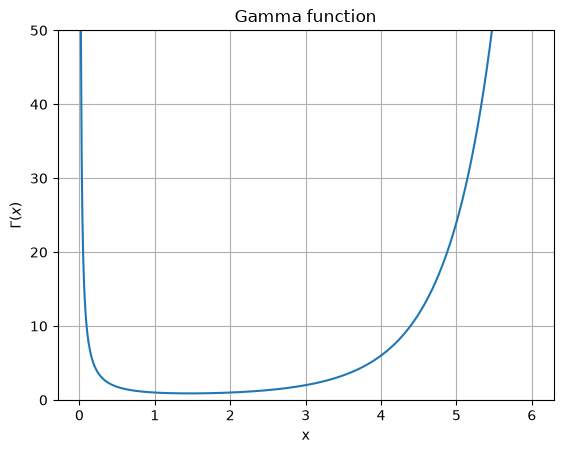

In [556]:
import matplotlib.pyplot as plt
from math import gamma as g
import numpy as np
x_range = np.arange(0,6,0.01)
x_range[0]=np.nan
plt.plot(x_range, [g(float(x)) for x in x_range])
plt.xlabel('x')
plt.ylabel(rf'$\Gamma(x)$')
plt.title('Gamma function')
plt.ylim(0,50)
plt.grid()

### Lower gamma function

For $\alpha>0$ and $z>0$ the *lower gamma function* is defined by 
$\gamma(\alpha,z):=\int_{0}^z x^{\alpha-1}e^{-x}dx$. 
Note that $\Gamma(\alpha)=\lim_{z\to \infty} \gamma(\alpha,z)$. 

The lower gamma function can essentially be found in `scipy`. However, it needs to be renormalized as illustrated below. 

C:\Users\Till Hauser\AppData\Local\Temp\ipykernel_49936\2627020869.py:5: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  return quad(lambda x: x**(alpha-1) * exp(-x), 0, z)[0] # [1] is an estimated error, [0] the estimated value of the integral


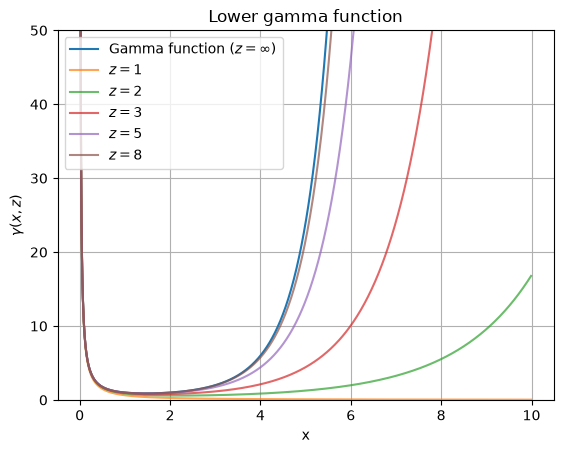

In [557]:
# Lower gamma function numerically:
from scipy.integrate import quad
from math import exp, gamma
def lower_gamma(alpha, z):
    return quad(lambda x: x**(alpha-1) * exp(-x), 0, z)[0] # [1] is an estimated error, [0] the estimated value of the integral

# Lower gamma via scipy:
from scipy.special import gammainc, gamma
def lower_gamma_np(alpha, z):
    return gamma(alpha) * gammainc(alpha, z)

# Visualization
import matplotlib.pyplot as plt
import numpy as np
from math import gamma

z_values= [1,2,3,5,8]
x_range = np.arange(0,10,0.01)
x_range[0]=np.nan
plt.plot(x_range, [gamma(float(x)) for x in x_range], label=rf"Gamma function ($z=\infty$)")
for z in z_values:
    plt.plot(x_range, [lower_gamma(float(x),z=z) for x in x_range], label=rf"$z={z}$", alpha = 0.7)
    #plt.plot(x_range, [lower_gamma_np(float(x),z=z) for x in x_range], label=rf"$z={z}$", alpha = 0.7)
plt.xlabel('x')
plt.ylabel(rf'$\gamma(x,z)$')
plt.title('Lower gamma function')
plt.ylim(0,50)
plt.legend()
plt.grid()


## Probability density function

For $\alpha, \lambda>0$ *Gamma distribution* is given by the probability density function
$f(x):=\frac{\lambda^\alpha}{\Gamma(\alpha)}  x^{\alpha-1}e^{-\lambda x} I_{[0,\infty)}(x).$

The parameter $\alpha$ is called the *shape parameter*, $\lambda$ is called the *rate* and $1/\lambda$ is called the *scale*. 
We write $X \sim \Gamma(\alpha, \lambda)$. 

The probability density function can be found in`scipy` via `scipy.stats.gamma.pdf(x, a=alpha, scale=1/rate)`. 

**Remark:**
1) For $\alpha=1$ it is called the *exponential distribution*. 
2) For integer $\alpha$ it is also called the *Erlang* distribution. 

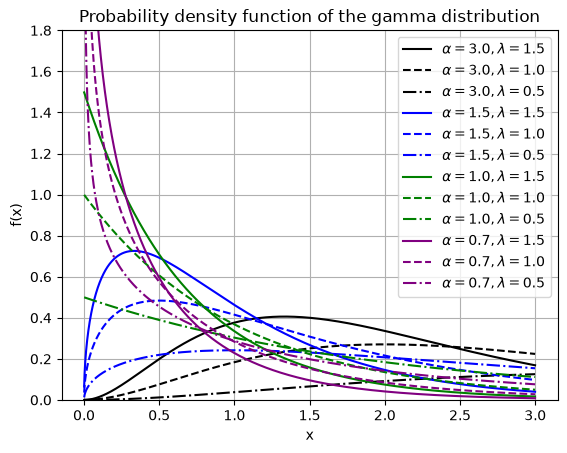

In [558]:
from math import gamma as g
from math import exp
import scipy
def gamma_distribution(alpha=1,rate=1): 
    return lambda x: (rate**alpha/g(alpha)) * (x**(alpha-1) * exp(-(rate*x))) if x>0 else 0

import numpy as np
from matplotlib import pyplot as plt

x_range = np.arange(0,3,0.001)
x_range[0]=np.nan
alphas = [3.0, 1.5, 1.0, 0.7]
colors = ["black", "blue", "green", "purple"]
rates = [1.5,1.0,0.5]
linestyles = ["-", "--", "-."]

for alpha in alphas:
    color = colors[alphas.index(alpha)]
    for rate in rates:
        linestyle = linestyles[rates.index(rate)]
        f = gamma_distribution(alpha=alpha, rate=rate)
        #f = lambda x: scipy.stats.gamma.pdf(x, a=alpha, scale=1/rate)
        label_string = rf'$\alpha={alpha}, \lambda = {rate}$'
        plt.plot(x_range, [f(x) for x in x_range], label=label_string, color=color, linestyle=linestyle)

plt.title(r'Probability density function of the gamma distribution')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.ylim(0, 1.8)
plt.grid()
plt.legend()
plt.show()

## Cumulative distribution function

**Proposition:**
The cumulative distribution function of the gamma distribution is given by 
$$
F_X(x)=\frac{\gamma(\alpha,\lambda x)}{\Gamma(\alpha)}I_{(0,\infty)}(x),
$$ 
where $\gamma$ is the lower incomplete gamma function.

*Proof:*
The statement is clear for $x\leq 0$. 
For $x> 0$  and with $t=\lambda y$ ($dt = \lambda dy$) we compute
\begin{align*}
    F_X(x)
    &=P(X\leq x)
    = \int_0^x \frac{1}{\Gamma(\alpha)} \lambda^\alpha y^{\alpha - 1} e^{-\lambda y} dy
    = \frac{\lambda^\alpha }{\Gamma(\alpha)} \int_0^x y^{\alpha - 1} e^{-\lambda y} dy\\
    &= \frac{\lambda^\alpha }{\Gamma(\alpha)} \int_0^{\lambda x} (\lambda^{-1}t)^{\alpha - 1} e^{-t} \lambda^{-1} dt
    = \frac{1}{\Gamma(\alpha)} \int_0^{\lambda x} t^{\alpha - 1} e^{-t} dt
    =\frac{\gamma(\alpha,\lambda x)}{\Gamma(\alpha)}.
    \qquad \blacksquare
\end{align*}

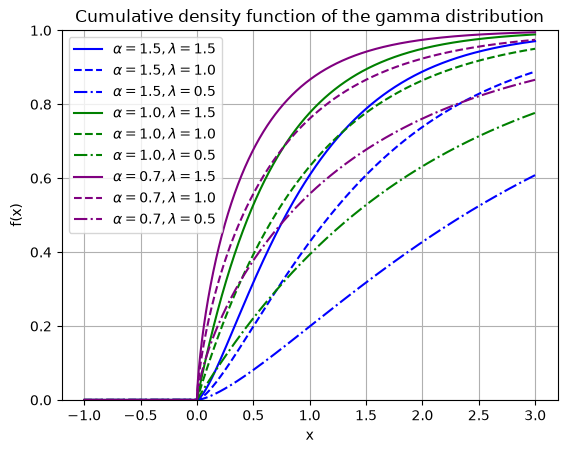

In [559]:
import scipy
import numpy as np
from matplotlib import pyplot as plt

x_range = np.arange(-1,3,0.001)
alphas = [1.5,1.0,0.7]
colors = ["blue", "green", "purple"]
rates = [1.5,1.0,0.5]
linestyles = ["-", "--", "-."]

for alpha in alphas:
    color = colors[alphas.index(alpha)]
    for rate in rates:
        linestyle = linestyles[rates.index(rate)]
        f = lambda x: scipy.stats.gamma.cdf(x, a=alpha, scale=1/rate)
        label_string = rf'$\alpha={alpha}, \lambda = {rate}$'
        plt.plot(x_range, [f(x) for x in x_range], label=label_string, color=color, linestyle=linestyle)

plt.title(r'Cumulative density function of the gamma distribution')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.ylim(0, 1)
plt.grid()
plt.legend()
plt.show()

## Rescaling gamma distributed random variables

Rescaling a gamma distributed random variable we obtain again a gamma distributed random variable, where the shape parameter is the same and the scale is rescaled. Note that the rate is transformed by deviding by the rescaling factor.  

**Proposition:**
For $c>0$ and $X\sim \Gamma(\alpha, \lambda)$ we have $cX \sim \Gamma(\alpha, \lambda/c)$. 

*Proof:*
For $Z\sim \Gamma(\alpha, \lambda /c)$ and a real $x$ we have
\begin{align*}
    F_{cX}(x)
    &= P(cX\leq x)
    = P(X\leq x/c)
    = F_X(x/c)\\
    &=\frac{\gamma(\alpha, \lambda x/c)}{\Gamma(\alpha)}I_{(0,\infty)}(x)\\
    &=\frac{\gamma(\alpha, (\lambda/c) x)}{\Gamma(\alpha)}I_{(0,\infty)}(x)
    =F_Z(x). 
    \qquad \blacksquare    
\end{align*}

A little computer experiment for illustration: 

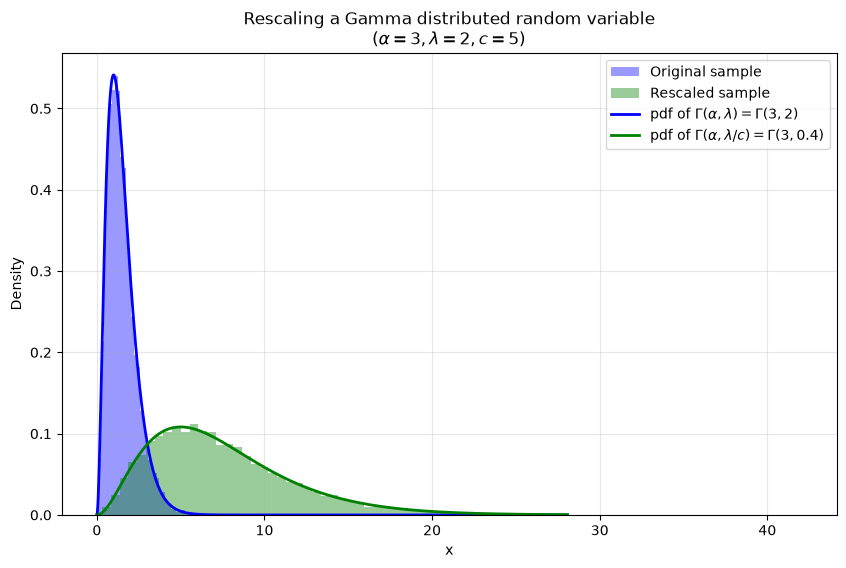

In [560]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

# PARAMETERS
alpha, rate = 3, 2
c = 5
sample_size = 10000

# Original Gamma distribution
rng = np.random.default_rng(42)
samples_X = rng.gamma(shape=alpha, scale=1/rate, size=sample_size)

# Rescaled random variable
samples_Z = c * samples_X

# VISUALIZATION
plt.figure(figsize=(10, 6))
plt.hist(samples_X, bins=50, density=True, alpha=0.4, label='Original sample', color = "blue")
plt.hist(samples_Z, bins=80, density=True, alpha=0.4, label='Rescaled sample', color = "green")
x_range = np.linspace(0, gamma.ppf(0.999, a=alpha, scale=c/rate), 1000)
pdf_X = gamma.pdf(x_range, a=alpha, scale=1/rate)
plt.plot(x_range, pdf_X, linewidth=2, label=rf'pdf of $\Gamma(\alpha,\lambda)=\Gamma({alpha},{rate})$', color = "blue")
pdf_Z = gamma.pdf(x_range, a=alpha, scale=c/rate)
plt.plot(x_range, pdf_Z, linewidth=2, label=rf'pdf of $\Gamma(\alpha,\lambda/c)=\Gamma({alpha},{rate/c})$', color = "green")

plt.xlabel('x')
plt.ylabel('Density')
plt.title('Rescaling a Gamma distributed random variable\n'+rf'($\alpha = {alpha}, \lambda = {rate}, c= {c}$)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Moment generating function

**Proposition:**
The moment generating function of $X\sim \Gamma(\alpha, \lambda)$ is given by 
$$
M_X(t)= \left(\frac{\lambda}{\lambda-t}\right)^\alpha
$$
for all $t<\lambda$. 

*Proof:*
With $y=(\lambda -t)x$, i.e. $dy = (\lambda -t) dx$ we have

\begin{align*}
    M_X(t)
    = \int_0^\infty e^{tx} \frac{1}{\Gamma(\alpha)} \lambda^\alpha x^{\alpha-1} e^{-\lambda x} dx
    = \frac{\lambda^\alpha}{\Gamma(\alpha)} \int_0^\infty x^{\alpha-1} e^{-(\lambda-t) x} dx
    = \frac{\lambda^\alpha}{\Gamma(\alpha)} \int_0^\infty \frac{1}{(\lambda -t)^{\alpha-1}}y^{\alpha-1} e^{-y} \frac{1}{\lambda -t}dy
    = \left(\frac{\lambda}{\lambda-t}\right)^\alpha \frac{\Gamma(\alpha)}{\Gamma(\alpha)}. 
    \qquad \blacksquare    
\end{align*}


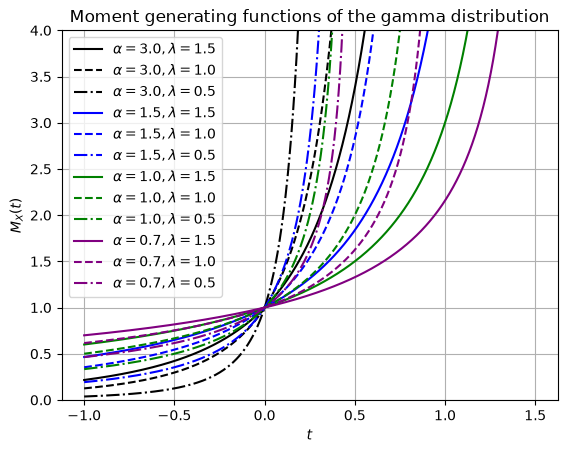

In [561]:
import numpy as np
from matplotlib import pyplot as plt

x_range = np.arange(-1,30,0.001)
alphas = [3.0, 1.5, 1.0, 0.7]
colors = ["black", "blue", "green", "purple"]
rates = [1.5,1.0,0.5]
linestyles = ["-", "--", "-."]

for alpha in alphas:
    color = colors[alphas.index(alpha)]
    for rate in rates:
        linestyle = linestyles[rates.index(rate)]
        M = lambda t : (rate/(rate-t))**alpha if t<rate else np.nan  
        label_string = rf'$\alpha={alpha}, \lambda = {rate}$'
        plt.plot(x_range, [M(x) for x in x_range], label=label_string, color=color, linestyle=linestyle)

plt.title(r'Moment generating functions of the gamma distribution')
plt.xlabel(r'$t$')
plt.ylabel(r'$M_X(t)$')
plt.ylim(0, 4)
plt.grid()
plt.legend()
plt.show()



## Expected value and variance

**Proposition:** For $X\sim \Gamma(\alpha,\lambda)$ we have 
1) $\mathbb{E}[X] = \frac{\alpha}{\lambda}$ and 
2) $\operatorname{Var}[X] = \frac{\alpha}{\lambda^2}$. 

*Proof:*
We compute 
$$
M_X'(t)= \lambda^\alpha (-\alpha) (\lambda-t)^{-\alpha-1}(-1)=\frac{\lambda^\alpha \alpha}{(\lambda-t)^{\alpha+1}} 
$$
and 
$$
M_X''(t)= \lambda^\alpha \alpha (-\alpha-1) (\lambda-t)^{-\alpha-2}(-1)=\frac{\lambda^\alpha \alpha(\alpha+1)}{(\lambda-t)^{\alpha+2}}.  
$$
Thus $\mathbb{E}[X] = M_X'(0) = \frac{\alpha}{\lambda}$ and 
$\operatorname{Var}[X] = M_X''(0)- \mathbb{E}[X]^2 = \frac{\alpha^2+\alpha}{\lambda^2}- \frac{\alpha^2}{\lambda^2}=\frac{\alpha}{\lambda^2}$. 
$    \qquad \blacksquare    $

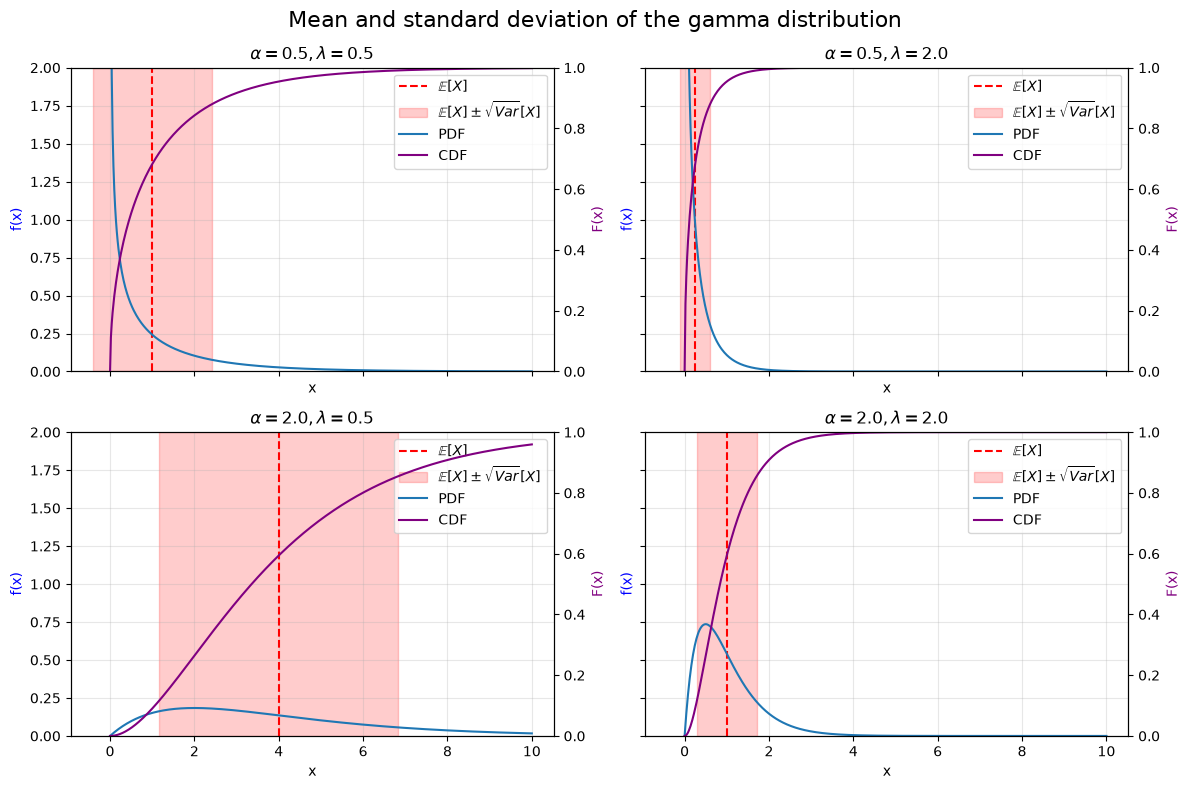

In [562]:
from matplotlib import pyplot as plt
from math import sqrt
import numpy as np
import scipy

rates = [0.5, 1, 2, 4]
parameters = [
    (0.5,0.5),
    (0.5,2.0),
    (2.0,0.5),
    (2.0,2.0)
]

x_min, x_max = 0, 10
steps = 500

x_range = np.linspace(x_min, x_max, steps)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
for ax, params in zip(axes.flat, parameters):
    alpha, rate = params[0], params[1]
    mean = alpha/rate
    variance = alpha/(rate**2)
    std = sqrt(variance)
    # Mean
    mean_label = rf'$\mathbb{{E}}[X]$'
    ax.axvline(x=mean, color='red', linestyle='--', label=mean_label)
    # STD
    std_label = rf'$\mathbb{{E}}[X]\pm\sqrt{{Var}}[X]$'
    ax.axvspan(mean-std, mean+std, color='red', alpha=0.2, label=std_label)
    # PDF
    ax.plot(x_range, scipy.stats.gamma.pdf(x_range, a=alpha, scale=1/rate), label="PDF")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)", color="blue")
    ax.set_title(fr"$\alpha = {alpha}, \lambda = {rate}$")
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 2)
    # CDF
    ax2 = ax.twinx()
    ax2.plot(x_range, scipy.stats.gamma.cdf(x_range, a= alpha, scale=1/rate), color='purple', linestyle='-', label="CDF")
    ax2.set_ylabel("F(x)", color="purple")
    ax2.set_ylim(0, 1)
    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2)
fig.suptitle("Mean and standard deviation of the gamma distribution", fontsize=16)
plt.tight_layout()
plt.show()

## Sum of gamma distributed random variables

**Theorem:** 
If $X_1,\dots, X_n$ are independent random variables with $X_i\sim \Gamma(\alpha_i,\lambda)$, then 
$\sum_{i=1}^n X_i \sim \Gamma(\sum_{i=0}^n \alpha_i, \lambda)$. 

*Proof:*
For $X:=\sum_{i=1}^n X_i$ and $t<\lambda$ we have
\begin{align*}
    M_X(t)
    =\mathbb{E}[e^{tX}]
    =\prod_{i=1}^n\mathbb{E}[e^{tX_i}] 
    =\prod_{i=1}^n\left(\frac{\lambda}{\lambda-t}\right)^{\alpha_i}
    =\left(\frac{\lambda}{\lambda-t}\right)^{\sum_{i=1}^n\alpha_i}. 
    \qquad \blacksquare    
\end{align*}

A little experiment for illustration.


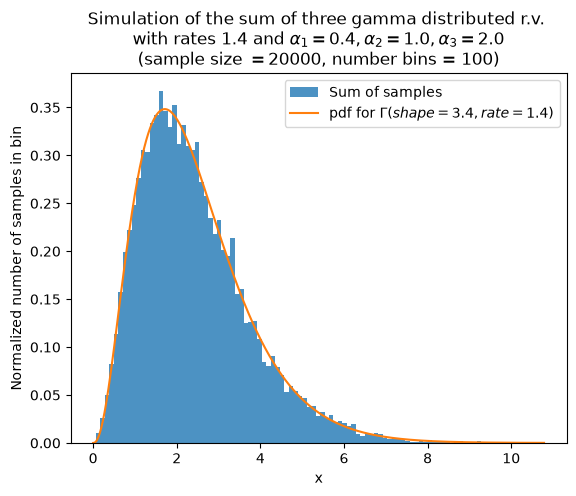

In [ ]:
import numpy as np

rate_individual = 1.4
alpha_1, alpha_2,alpha_3 = 0.4, 1.0, 2.0
sum_alphas = alpha_1 + alpha_2 + alpha_3

# SAMPLING
sample_size = 20000
# Simulate samples from the respective gamma distributions
samples_1 = np.random.gamma(shape=alpha_1, scale=1/rate_individual, size=sample_size)
samples_2 = np.random.gamma(shape=alpha_2, scale=1/rate_individual, size=sample_size)
samples_3 = np.random.gamma(shape=alpha_3, scale=1/rate_individual, size=sample_size)
# Compute the pairwise sum
samples_sum = samples_1 + samples_2 + samples_3

# VISUALIZATOIN
number_bins, step = 100, 0.001
x_range = np.arange(step, max(samples_sum), step)
plt.hist(samples_sum, bins = number_bins, density= True, alpha=0.8, label = rf"Sum of samples")
plt.plot(x_range, scipy.stats.gamma.pdf(x_range, a=sum_alphas, scale=1/rate_individual), label=rf"pdf for $\Gamma(shape={sum_alphas},rate={rate_individual})$")
plt.title(rf'Simulation of the sum of three gamma distributed r.v. '+'\n'+rf'with rates {rate_individual} and shapes '+rf'$\alpha_1={alpha_1}, \alpha_2={alpha_2}, \alpha_3={alpha_3}$'+'\n'+rf'(sample size $= {sample_size}$, number bins = {number_bins})')
plt.xlabel('x')
plt.ylabel('Normalized number of samples in bin')
plt.legend()
plt.show()

## Relationship with the exponential distribution

Recall that the exponential distribution (with rate $\lambda$) is given by $\Gamma(1,\lambda)$. 
Furthermore, from the result above it follows that the sum of $n$ iid exponential distributed random variables (with rate $\lambda$) is gamma distributed with shape parameter $n$ and the same rate. 
This result can be interpreted as follows. 
While the exponential distribution can describe the arrival time of a new costumer the gamma distribution with the same rate and shape parameter $n$ descries the time of the event of the nth new costumer. 

## Simulation

The gamma distribution can easily be simulated via the modules `random`, `numpy` or `scipy`. 

0.8681953229509711


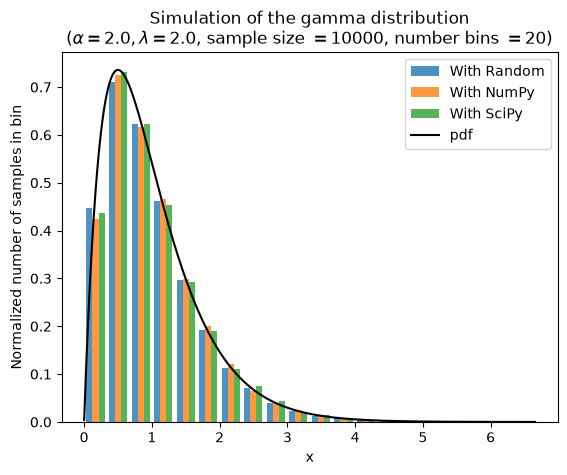

In [564]:
import random, scipy

alpha = 2.0 # Shape parameter
rate = 2.0  # Rate parameter

# A single sample:
x = random.expovariate(rate)
print(x)

# A whole sample:
sample_size = 10000
label_1 = "With Random"
samples_1 = [
    random.gammavariate(alpha, 1/rate)
    for _ in range(sample_size)
]

label_2 = "With NumPy"
samples_2 = np.random.gamma(
    shape=alpha,
    scale=1/rate,
    size=sample_size
)

label_3 = "With SciPy"
samples_3 = scipy.stats.gamma.rvs(
    a=alpha,
    scale=1/rate,
    size=sample_size
)


# Visualization of the samples
number_bins = 20

plt.hist(
    [samples_1, samples_2, samples_3],
    bins=number_bins,
    density=True,
    label=[label_1, label_2, label_3],
    histtype="bar",
    alpha=0.8
)

#plt.hist(samples, bins = number_bins, density= True, alpha=0.6)

step = 0.001
maximum = max(max(samples_1),max(samples_2),max(samples_3))
x_range = np.arange(step, maximum, step)
f = lambda x : scipy.stats.gamma.pdf(x, a=alpha, scale=1/rate)
plt.plot(x_range, f(x_range), label="pdf", color = "black")

plt.title('Simulation of the gamma distribution\n'+rf'($\alpha={alpha}, \lambda={rate}$, sample size $= {sample_size}$, number bins $= {number_bins}$)')
plt.xlabel('x')
plt.ylabel('Normalized number of samples in bin')
plt.legend()
plt.show()